# Insider Threat & User Behaviour Analytics from Logs — Phase 1

**CET433 Selected Topics in Cyber · Fall 2026 · Project 8**
Instructors: Dr. Mariam Labib, Eng. Maryam Adel

| Member | Phase 1 responsibility |
|---|---|
| **Mohamed Moamen** (team leader) | Problem & market case, privacy/ethics note, integration, talk |
| Ahmed Mohamed | Data acquisition, log schema, cleaning & EDA |
| Marwan Hassan | Per-user daily feature engineering & labelling |
| Ahmed Osama | Pipeline, leakage checks, baseline model & metrics |

**Phase 1 deliverables in this notebook:** market case · privacy & ethics note · dataset & licence · log schema ·
EDA · cleaning · per-user daily feature table · split-before-fit pipeline · leakage checks · class-imbalance handling ·
baseline with confusion matrix, precision, recall, F1 · business metric · Phase 2 plan & risks.

> Run top-to-bottom with **Runtime → Run all**. Defaults use a *synthetic* dataset in the exact CERT r4.2 format;
> set `USE_SYNTHETIC = False` in §3 to run on the real CERT r4.2 files.

In [1]:
# 0. Setup: works in Google Colab and locally
import os, sys, subprocess

REPO_URL = "https://github.com/YOUR-TEAM/insider-threat-uba.git"   # <-- set to your team's GitHub repo

if not os.path.isdir("src/uba"):
    if os.path.isdir("../src/uba"):
        os.chdir("..")                                # opened from notebooks/
    elif "google.colab" in sys.modules:
        if not os.path.isdir("insider-threat-uba"):
            subprocess.run(["git", "clone", "-q", REPO_URL, "insider-threat-uba"], check=True)
        os.chdir("insider-threat-uba")
    else:
        raise RuntimeError("Run from the repository root or the notebooks/ folder.")
sys.path.insert(0, os.path.abspath("src"))
print("Working directory:", os.getcwd())

Working directory: C:\Users\ahmad\Downloads\Select topic\insider-threat-uba


In [2]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import set_config

from uba.synthetic_cert import generate_synthetic_cert
from uba.data_loading import load_insider_answers
from uba.features import build_from_dir, FEATURE_DESCRIPTIONS
from uba.modeling import (SEED, TARGET, time_split, feature_columns, build_baseline_pipeline,
                          rule_baseline, leakage_checks, prefix_invariance_check, signed_log1p)
from uba.evaluation import (CostAssumptions, classification_metrics, business_metrics, results_table,
                            insider_level_detection, plot_confusion, plot_pr_curves, cost_assumptions_dict)

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(SEED)                       # fixed seed everywhere (generator, models)
set_config(display="diagram")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50, "display.width", 160)
FIG_DIR = Path("reports/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

## 1. Problem and market case

**Customer.** The insider-risk / security team of a **mid-sized bank (~2,000 employees)**, and the
data-loss-prevention (DLP) or HR-compliance vendors that sell to such teams. Banks are a good first
customer: they hold valuable customer and financial data, regulators expect an insider-risk programme,
and they already collect the needed logs (Active Directory logons, endpoint USB control, mail gateway,
web proxy).

**The threat and its cost.** Insiders (employees, contractors) steal data or sabotage systems **using
access they legitimately have**, so perimeter controls and signature-based tools do not see them. The
Ponemon Institute *Cost of Insider Threats Global Report (2022)* puts the average annual cost of insider
incidents at about **USD 15.4 M per organisation**, about **USD 650 k per malicious-insider
incident**, and an average **85 days to contain** an incident. *(Verify against the latest edition
before the talk.)*

**Why AI helps.** Static rules ("alert on any USB use after 19:00") either drown analysts in alerts or
miss slow, low-volume theft. Machine learning can (i) learn a **behaviour baseline per user and per role**,
(ii) combine weak signals across logon, device, file, e-mail and web logs into one risk score, and
(iii) rank user-days so analysts review the riskiest first.

**Unit of analysis.** One **user-day** (a user's activity on one calendar day). The model scores each
user-day; analysts receive the top-ranked user-days as a watch-list.

**Success metric (defined up front).**
* **Primary:** *recall* of malicious user-days, at a **workable alert budget of ≤ 5 alerts per 1,000 users
  per day**. Missing an insider is much more costly than one extra review, so recall is weighted above precision.
* **Reported alongside:** precision, F1, F2 (recall-weighted), **PR-AUC** (threshold-free, robust to the
  <1 % positive rate), the confusion matrix, and **insider-level detection** (was each insider flagged at
  least once, and how many days after their first malicious act).
* **Business metric:** analyst hours spent on alerts + estimated cost of missed malicious user-days (§12).
* **Accuracy is *not* used to select models:** with ~0.4 % malicious user-days, a model that never
  raises an alert is 99.6 % accurate and useless.
* **Phase 2 target:** recall ≥ 0.80 with precision ≥ 0.30 on the test period, and every test-period
  insider flagged within 3 days of starting.

## 2. Privacy and ethics note

User behaviour analytics watches **people**, not machines, so it can cause real harm if it is misused.

1. **Data.** We use only the public, fully **synthetic** CERT Insider Threat Test Dataset (no real
   employees) and, until it is downloaded, a synthetic generator in the same format. No real
   organisation's logs are collected. E-mail and web *content* columns are never loaded; we use metadata
   counts only (data minimisation).
2. **Pseudonymisation.** Models see behaviour counts and job role, never names, e-mail addresses or
   psychometric scores. User IDs are kept only to join tables and to route an alert; they are not model inputs.
3. **Decision support, not verdicts.** A high score means "worth a closer look", **not** "guilty".
   Every alert must be reviewed by a trained analyst, follow a documented HR/legal process, and the
   employee must have a right to respond. The system must never trigger automatic sanctions.
4. **False accusations are the main harm.** False positives cost analyst time *and* can damage an
   innocent employee's reputation. So we report false positives explicitly, keep alert volumes low,
   and in Phase 2 we will measure **false-positive impact per role** (e.g. are IT admins or on-call
   staff flagged unfairly often?).
5. **Proportionality and transparency.** In a real deployment, monitoring must be disclosed in the
   acceptable-use policy, be lawful under local law (e.g. GDPR-style data-protection rules and labour law),
   keep data only for a limited period, and restrict who can see scores.
6. **Bias.** Role and working-pattern features may correlate with protected traits (e.g. carers working
   unusual hours). Features are behaviour-based, psychometric data is excluded, and Phase 2 will audit
   error rates across roles.

## 3. Dataset: source and licence

| | |
|---|---|
| **Primary dataset** | **CERT Insider Threat Test Dataset, release r4.2**, Carnegie Mellon University Software Engineering Institute (CERT Division) with ExactData LLC |
| **Where** | CMU KiltHub: <https://kilthub.cmu.edu/articles/dataset/Insider_Threat_Test_Dataset/12841247> |
| **Licence** | Distributed for research use; the licence/copyright terms are in `license.txt` inside the archive (ExactData terms). **Cite the KiltHub record; read `license.txt` after downloading and quote it in the report.** |
| **Content** | ~1,000 synthetic employees over ~17 months; `logon`, `device`, `file`, `email`, `http` logs, monthly `LDAP` snapshots, `psychometric.csv`; separate `answers` archive with labelled insiders (scenarios 1–3 in r4.2) |
| **Size** | ~1.3 GB zipped, ~16 GB unzipped (most of it `http.csv`) |
| **Second source (Phase 2)** | LANL *Comprehensive, Multi-Source Cyber-Security Events* authentication logs (<https://csr.lanl.gov/data/cyber1/>), for checking generalisation |

**What runs below.** The team has not downloaded r4.2 yet, so the notebook defaults to a **synthetic dataset
written in exactly the r4.2 format**: same files, columns, timestamp format, LDAP layout and answers layout.
The generator plays out the three r4.2 insider scenarios and adds realistic benign look-alikes (on-call
staff, heavy-but-legitimate USB users, casual job-site visits, ordinary leavers). **Every downstream cell is
unchanged when `USE_SYNTHETIC = False`.** All numbers in this notebook are therefore *pipeline-validation*
results and must be re-run on r4.2 before submission.

In [3]:
USE_SYNTHETIC = True                      # False -> use the real CERT r4.2 files below

if USE_SYNTHETIC:
    DATA_DIR = generate_synthetic_cert("data/raw/synthetic_r4.2", n_users=200, n_days=270, seed=SEED)
    ANSWERS_DIR = DATA_DIR / "answers"
else:
    # Download r4.2.tar.bz2 + answers.tar.bz2 from KiltHub and extract to data/raw/
    # (in Colab: mount Google Drive and point these paths there)
    DATA_DIR = Path("data/raw/r4.2")
    ANSWERS_DIR = Path("data/raw/answers")

print("DATA_DIR   :", DATA_DIR.resolve())
print("ANSWERS_DIR:", ANSWERS_DIR.resolve())
print(sorted(p.name for p in DATA_DIR.iterdir()))

DATA_DIR   : C:\Users\ahmad\Downloads\Select topic\insider-threat-uba\data\raw\synthetic_r4.2
ANSWERS_DIR: C:\Users\ahmad\Downloads\Select topic\insider-threat-uba\data\raw\synthetic_r4.2\answers
['LDAP', 'answers', 'device.csv', 'email.csv', 'file.csv', 'http.csv', 'logon.csv', 'psychometric.csv']


## 4. Log schema

Five event logs share the key `(id, date, user, pc)`. `date` is `MM/DD/YYYY HH:MM:SS`. The LDAP folder holds
one HR snapshot per month (leavers disappear). Ground truth is in `answers/insiders.csv` plus one file per
insider listing their malicious events.

In [4]:
schema = {
    "logon.csv":  ("Windows logon/logoff",                    "activity ∈ {Logon, Logoff}"),
    "device.csv": ("Removable media (USB) connect/disconnect", "activity ∈ {Connect, Disconnect}"),
    "file.csv":   ("Files copied to removable media",         "filename, content (content not used)"),
    "email.csv":  ("Sent e-mail metadata",                    "to/cc/bcc (';'-separated), from, size (bytes), attachments (count)"),
    "http.csv":   ("Web proxy requests",                      "url, content (content not used)"),
}
rows = []
for f, (desc, notes) in schema.items():
    head = pd.read_csv(DATA_DIR / f, nrows=3)
    with open(DATA_DIR / f, "rb") as fh:
        n = sum(1 for _ in fh) - 1
    rows.append({"file": f, "what it records": desc, "columns": ", ".join(head.columns), "rows": f"{n:,}", "notes": notes})
ldap_example = pd.read_csv(sorted((DATA_DIR / "LDAP").glob("*.csv"))[0], nrows=3)
rows.append({"file": "LDAP/YYYY-MM.csv", "what it records": "Monthly HR directory snapshot",
             "columns": ", ".join(ldap_example.columns), "rows": f"{len(list((DATA_DIR/'LDAP').glob('*.csv')))} files", "notes": "role, unit, supervisor"})
rows.append({"file": "answers/insiders.csv", "what it records": "Ground-truth insiders",
             "columns": "dataset, scenario, details, user, start, end", "rows": "", "notes": "details -> per-insider event file"})
display(pd.DataFrame(rows).style.hide(axis="index"))
for f in ["logon.csv", "device.csv", "file.csv", "email.csv", "http.csv"]:
    print(f"\n--- {f}"); display(pd.read_csv(DATA_DIR / f, nrows=3))

file,what it records,columns,rows,notes
logon.csv,Windows logon/logoff,"id, date, user, pc, activity","77,036","activity ∈ {Logon, Logoff}"
device.csv,Removable media (USB) connect/disconnect,"id, date, user, pc, activity","24,236","activity ∈ {Connect, Disconnect}"
file.csv,Files copied to removable media,"id, date, user, pc, filename, content","25,049","filename, content (content not used)"
email.csv,Sent e-mail metadata,"id, date, user, pc, to, cc, bcc, from, size, attachments, content","391,396","to/cc/bcc (';'-separated), from, size (bytes), attachments (count)"
http.csv,Web proxy requests,"id, date, user, pc, url, content","429,368","url, content (content not used)"
LDAP/YYYY-MM.csv,Monthly HR directory snapshot,"employee_name, user_id, email, role, business_unit, functional_unit, department, team, supervisor",9 files,"role, unit, supervisor"
answers/insiders.csv,Ground-truth insiders,"dataset, scenario, details, user, start, end",,details -> per-insider event file



--- logon.csv


,id,date,user,pc,activity
0,{3N2Z-IXKWVEQG-EHPFWY4D},01/04/2010 06:31:59,JBA4929,PC-4120,Logon
1,{U5DP-S7T1RCE5-L6AQN9MI},01/04/2010 06:37:41,TWD3524,PC-4408,Logon
2,{5VLW-HSOEMNUD-XXZHJMV7},01/04/2010 06:44:30,XBS4998,PC-4270,Logon



--- device.csv


,id,date,user,pc,activity
0,{FIIP-AQC1ZZ4V-XZASQFP7},01/04/2010 07:09:21,DOK7001,PC-5431,Connect
1,{SB7Z-F1VJLWAV-067FZ4RR},01/04/2010 07:13:29,DOK7001,PC-5431,Disconnect
2,{FSF4-G44BHHXO-L1AOKY6T},01/04/2010 07:54:01,DLA3582,PC-9546,Connect



--- file.csv


,id,date,user,pc,filename,content
0,{0L89-0W9TKK73-PZDE14Q5},01/04/2010 07:12:18,DOK7001,PC-5431,MOE6KLN7.zip,status review release design update
1,{QQFZ-UN2LBP3J-SUQACB5S},01/04/2010 07:12:57,DOK7001,PC-5431,C2U73JOY.pdf,order customer policy budget update
2,{T3DN-RTRAMV0K-4AFGH36M},01/04/2010 07:12:59,DOK7001,PC-5431,ZQ039MUZ.jpg,lunch budget meeting budget project



--- email.csv


,id,date,user,pc,to,cc,bcc,from,size,attachments,content
0,{7V7O-846UKC2E-S99UYC63},01/04/2010 06:42:24,TWD3524,PC-4408,Paula.Ortiz.9041@dtaa.com;Zane.Mercer.7503@dta...,NaN,NaN,Tara.Dawson.3524@dtaa.com,50257,0,quality project update network meeting invoice
1,{4AER-V1TK21IS-RPC4RIG2},01/04/2010 06:46:11,JBA4929,PC-4120,Dalia.Hassan.6945@dtaa.com;Dina.Young.2462@dta...,NaN,NaN,Jana.Abbott.4929@dtaa.com,6376,0,project travel lunch backup status network
2,{166L-20NDUSD9-PS21M6FX},01/04/2010 07:05:18,DOK7001,PC-5431,Ethan.Turner.2702@dtaa.com;Jana.Mercer.2331@dt...,NaN,NaN,Dalia.Keller.7001@dtaa.com,30429,1,network schedule quality lunch release budget



--- http.csv


,id,date,user,pc,url,content
0,{GRHL-34DY7110-WCWE2Q5U},01/04/2010 07:06:37,WCR4751,PC-2589,http://google.com/mtnwxi,training design design status meeting
1,{ZQLR-LZBR0UPW-JWYXL14Q},01/04/2010 07:10:25,ABO1925,PC-9386,http://wikipedia.org/ymlsum,report status meeting policy order
2,{HLM0-VIQVZ0EK-290A6TDK},01/04/2010 07:10:37,EDK5757,PC-7976,http://intranet.dtaa.com/jofyzx,network policy training design test


## 5. Loading and cleaning

`build_from_dir` loads each log **without the large free-text `content` columns**, cleans it, aggregates
it into user-day features, and reads the labels. Cleaning steps per log:

* drop duplicate event `id`s; drop rows missing `date`, `user` or `pc`;
* parse timestamps with the fixed format (unparseable dates are counted and dropped);
* normalise case (user, pc, e-mail addresses, URLs, file names), and convert `size`/`attachments` to numbers;
* sort chronologically. `http.csv` is processed in **1 M-row chunks** so the 14 GB real file fits in Colab RAM.

In [5]:
%%time
build = build_from_dir(DATA_DIR, ANSWERS_DIR, save_to="data/processed/user_day_features.csv")
table = build.table
display(pd.DataFrame([r.as_dict() for r in build.reports]).style.hide(axis="index"))
print("User-day feature table:", table.shape)

log,rows_in,duplicate_ids,missing_user/date/pc,unparseable_dates,rows_out
logon,77036,0,0,0,77036
device,24236,0,0,0,24236
file,25049,0,0,0,25049
email,391396,0,0,0,391396
http,429368,0,0,0,429368


User-day feature table: (36248, 41)
CPU times: total: 5.41 s
Wall time: 5.49 s


## 6. Exploratory data analysis (unlabelled, whole timeline)

This section only describes *behaviour* and does not look at labels, so using the whole timeline is safe.
Label-aware EDA (benign vs malicious) is done **on the training period only** in §9.

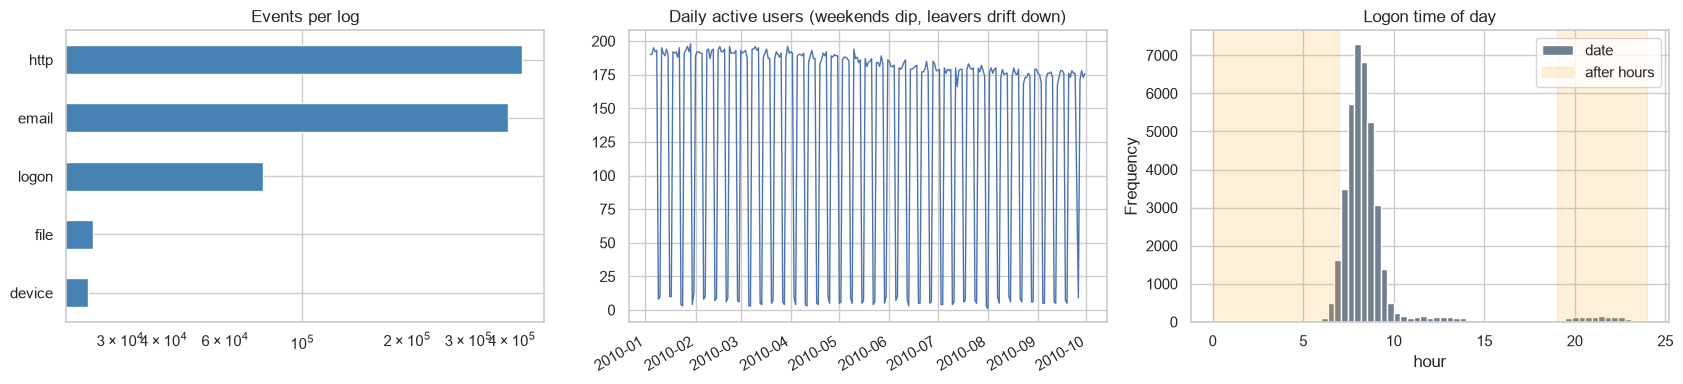

In [6]:
logon = build.logs["logon"]
counts = {k: len(v) for k, v in build.logs.items()} | {"http": int(build.aggs["http"]["n_http"].sum())}
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
pd.Series(counts).sort_values().plot.barh(ax=ax[0], color="steelblue"); ax[0].set_title("Events per log"); ax[0].set_xscale("log")
dau = logon[logon.activity == "Logon"].groupby(logon.date.dt.normalize())["user"].nunique()
dau.plot(ax=ax[1], lw=1); ax[1].set_title("Daily active users (weekends dip, leavers drift down)"); ax[1].set_xlabel("")
lh = logon[logon.activity == "Logon"].date
(lh.dt.hour + lh.dt.minute / 60).plot.hist(bins=48, ax=ax[2], color="slategray")
ax[2].axvspan(0, 7, color="orange", alpha=.15); ax[2].axvspan(19, 24, color="orange", alpha=.15, label="after hours")
ax[2].set_title("Logon time of day"); ax[2].set_xlabel("hour"); ax[2].legend()
plt.tight_layout(); savefig("eda_overview"); plt.show()

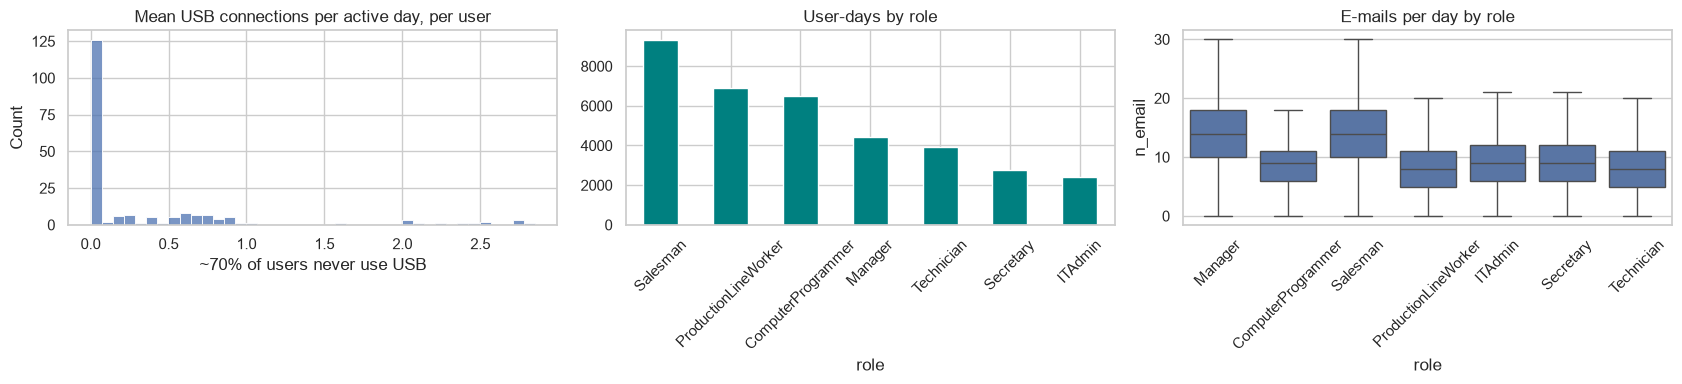

,count,mean,min,25%,50%,75%,max,std
day,36248,2010-05-15 11:45:18.075480,2010-01-04 00:00:00,2010-03-09 00:00:00,2010-05-13 00:00:00,2010-07-22 00:00:00,2010-09-30 00:00:00,NaN
n_logon,36248.0,1.062624,0.0,1.0,1.0,1.0,3.0,0.247694
n_after_hours_logon,36248.0,0.091508,0.0,0.0,0.0,0.0,2.0,0.29617
first_logon_hour,36238.0,8.198148,6.0,7.7,8.166667,8.633333,13.983333,0.795257
n_pcs,36248.0,1.02916,1.0,1.0,1.0,1.0,3.0,0.168422
last_logoff_hour,36248.0,17.0764,0.083333,16.45,16.966667,17.483333,23.983333,1.274633
n_usb,36248.0,0.334308,0.0,0.0,0.0,0.0,12.0,0.863531
n_usb_after_hours,36248.0,0.004855,0.0,0.0,0.0,0.0,4.0,0.08585
n_file,36248.0,0.691045,0.0,0.0,0.0,0.0,70.0,2.208271
n_file_after_hours,36248.0,0.012856,0.0,0.0,0.0,0.0,17.0,0.297125


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
per_user = table.groupby("user")[["n_usb", "n_email", "n_http"]].mean()
sns.histplot(per_user["n_usb"], bins=40, ax=ax[0]); ax[0].set_title("Mean USB connections per active day, per user")
ax[0].set_xlabel("~70% of users never use USB")
table["role"].value_counts().plot.bar(ax=ax[1], color="teal"); ax[1].set_title("User-days by role"); ax[1].tick_params(axis="x", rotation=45)
sns.boxplot(data=table, x="role", y="n_email", ax=ax[2], showfliers=False); ax[2].set_title("E-mails per day by role")
ax[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); savefig("eda_users_roles"); plt.show()
display(table.describe().T.round(2))

## 7. Per-user daily feature table

Each row is **one user on one day**. Features are counts from that day's events, plus **personal-baseline
features** that compare today with the same user's *previous* days (`*_dev`, `first_usb_ever`). These
history features use only past rows (`cumsum` minus today, then divided by the number of prior days), so no
future information enters; §10 tests this directly.

In [8]:
num_cols, cat_cols = feature_columns(table)
fd = pd.DataFrame([(k, *v) for k, v in FEATURE_DESCRIPTIONS.items()], columns=["feature", "source", "description"])
fd["used"] = fd.feature.isin(num_cols + cat_cols)
display(fd.style.hide(axis="index"))
print(f"{len(num_cols)} numeric + {len(cat_cols)} categorical features")
display(table[["user", "day"] + num_cols[:12] + ["role", TARGET]].head())

feature,source,description,used
n_logon,logon,Logon events that day,True
n_after_hours_logon,logon,"Logons before 07:00, from 19:00, or on a weekend",True
first_logon_hour,logon,Hour (fractional) of the first logon,True
last_logoff_hour,logon,Hour (fractional) of the last logoff (NaN if none -> imputed),True
n_pcs,logon,Distinct PCs the user touched (e.g. a colleague's machine),True
n_usb,device,Removable-media (USB) connections,True
n_usb_after_hours,device,USB connections after hours,True
n_file,file,Files copied to removable media,True
n_file_after_hours,file,File copies after hours,True
n_file_doc,file,Copied documents (.doc/.pdf/.txt/office),True


35 numeric + 2 categorical features


,user,day,n_logon,n_after_hours_logon,first_logon_hour,n_pcs,last_logoff_hour,n_usb,n_usb_after_hours,n_file,n_file_after_hours,n_file_doc,n_file_exe,n_file_zip,role,label
0,ABN9482,2010-01-04,1,0,8.700000,1,16.933333,0,0,0,0,0,0,0,Manager,0
1,ABO1925,2010-01-04,1,1,6.883333,1,15.950000,0,0,0,0,0,0,0,ComputerProgrammer,0
2,ADH4091,2010-01-04,1,0,7.833333,1,16.283333,0,0,0,0,0,0,0,Manager,0
3,ADU8566,2010-01-04,1,0,7.750000,1,17.183333,0,0,0,0,0,0,0,Salesman,0
4,AFF7267,2010-01-04,1,0,7.716667,1,17.200000,0,0,0,0,0,0,0,ProductionLineWorker,0


## 8. Split before fitting: time-based

We split **by calendar time**: the first 70 % of days are training, the last 30 % are the test. This matches
deployment (train on the past, score the future) and stops the model from learning an insider's later
behaviour and being tested on earlier days. **Nothing is fitted before this split**: imputation, scaling and
encoding are all inside the model `Pipeline` and are fitted on the training rows only. The random seed is fixed (`SEED = 42`).

,period,user-days,malicious user-days,malicious rate,insiders
train,2010-01-04 → 2010-07-10,25716,95,0.369%,7
test,2010-07-11 → 2010-09-30,10532,46,0.437%,4


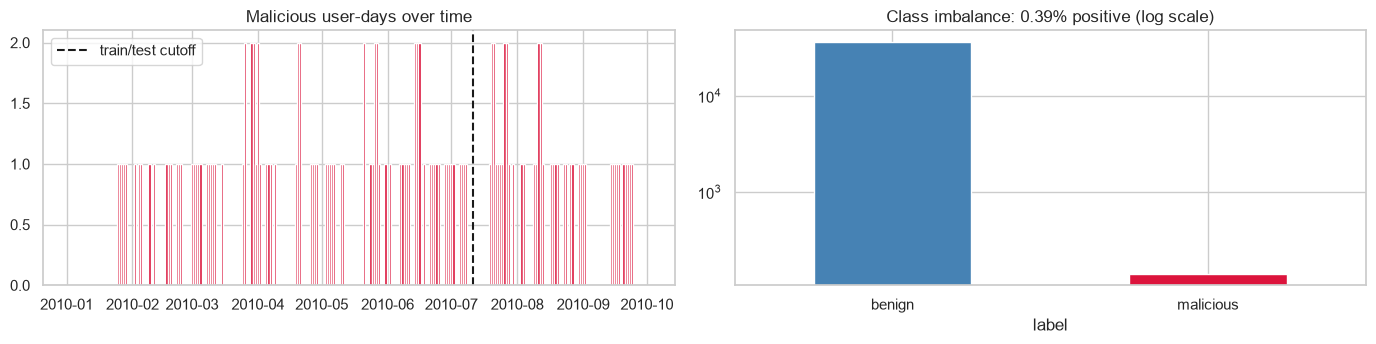

In [9]:
train, test, cutoff = time_split(table, test_frac=0.30)
summary = pd.DataFrame({
    "period": [f"{train.day.min().date()} → {train.day.max().date()}", f"{test.day.min().date()} → {test.day.max().date()}"],
    "user-days": [len(train), len(test)],
    "malicious user-days": [int(train[TARGET].sum()), int(test[TARGET].sum())],
    "malicious rate": [f"{train[TARGET].mean():.3%}", f"{test[TARGET].mean():.3%}"],
    "insiders": [train.loc[train[TARGET]==1, "user"].nunique(), test.loc[test[TARGET]==1, "user"].nunique()],
}, index=["train", "test"])
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
daily = table.groupby("day")[TARGET].sum()
ax[0].bar(daily.index, daily.values, width=1, color="crimson"); ax[0].axvline(cutoff, c="k", ls="--", label="train/test cutoff")
ax[0].set_title("Malicious user-days over time"); ax[0].legend()
table[TARGET].value_counts().rename({0: "benign", 1: "malicious"}).plot.bar(ax=ax[1], color=["steelblue", "crimson"], logy=True)
ax[1].set_title(f"Class imbalance: {table[TARGET].mean():.2%} positive (log scale)"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); savefig("split_and_imbalance"); plt.show()

## 9. Label-aware EDA (training period only)

How do malicious user-days differ from benign ones? We use the **training split only**, so feature and model
choices are not shaped by the test set.

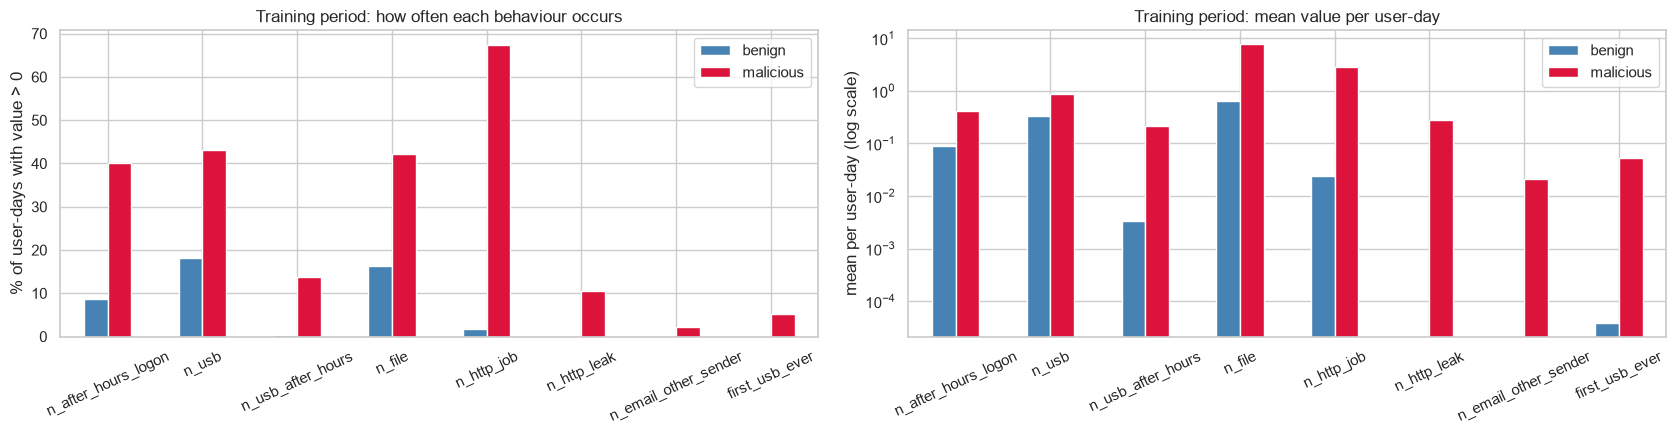

% days > 0             mean          
                         benign malicious benign malicious
n_after_hours_logon         8.7      40.0   0.09      0.41
n_usb                      18.1      43.2   0.33      0.87
n_usb_after_hours           0.3      13.7   0.00      0.21
n_file                     16.3      42.1   0.65      7.62
n_http_job                  1.7      67.4   0.02      2.84
n_http_leak                 0.0      10.5   0.00      0.27
n_email_other_sender        0.0       2.1   0.00      0.02
first_usb_ever              0.0       5.3   0.00      0.05

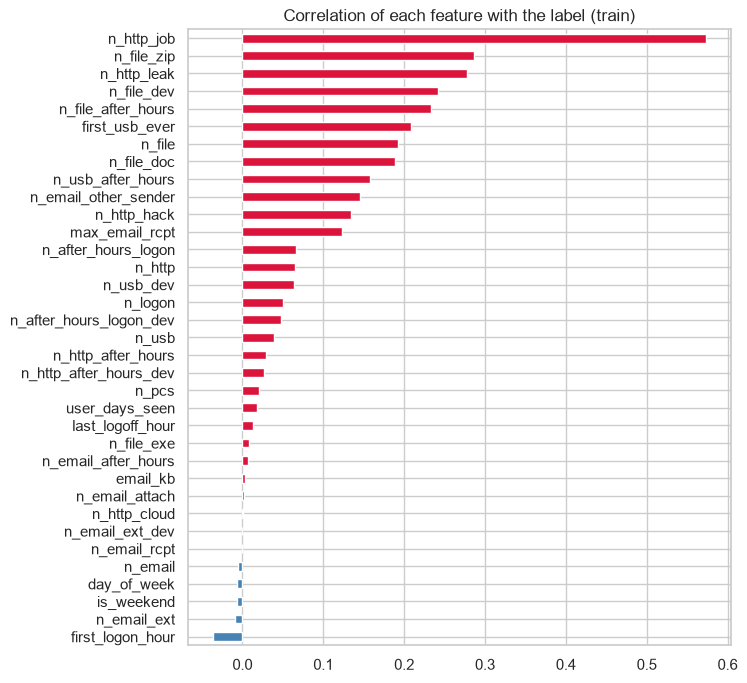

,insiders
scenario,
1 · after-hours USB + leak upload,4
2 · job hunting + data theft,4
3 · admin keylogger + mass mail,3


In [10]:
key = ["n_after_hours_logon", "n_usb", "n_usb_after_hours", "n_file", "n_http_job", "n_http_leak",
       "n_email_other_sender", "first_usb_ever"]
# most counts are zero on most days, so compare HOW OFTEN each behaviour occurs, and its mean
present = (train[key] > 0).groupby(train[TARGET]).mean().T * 100
present.columns = ["benign", "malicious"]
means = train.groupby(TARGET)[key].mean().T
means.columns = ["benign", "malicious"]
fig, ax = plt.subplots(1, 2, figsize=(17, 4.5))
present.plot.bar(ax=ax[0], color=["steelblue", "crimson"])
ax[0].set_ylabel("% of user-days with value > 0"); ax[0].set_title("Training period: how often each behaviour occurs")
means.plot.bar(ax=ax[1], color=["steelblue", "crimson"], logy=True)
ax[1].set_ylabel("mean per user-day (log scale)"); ax[1].set_title("Training period: mean value per user-day")
for a in ax: a.tick_params(axis="x", rotation=25)
plt.tight_layout(); savefig("eda_benign_vs_malicious"); plt.show()
display(pd.concat({"% days > 0": present.round(1), "mean": means.round(2)}, axis=1))

corr = train[num_cols].corrwith(train[TARGET]).sort_values()
plt.figure(figsize=(7, 8)); corr.plot.barh(color=np.where(corr > 0, "crimson", "steelblue"))
plt.title("Correlation of each feature with the label (train)"); savefig("feature_label_corr"); plt.show()

ins = load_insider_answers(ANSWERS_DIR)
display(ins.groupby("scenario").agg(insiders=("user", "count")).rename(index={
    1: "1 · after-hours USB + leak upload", 2: "2 · job hunting + data theft", 3: "3 · admin keylogger + mass mail"}))

## 10. Preprocessing pipeline and leakage check

**One `Pipeline` per model.** The `ColumnTransformer` does:
* numeric → `SimpleImputer(median)` → `signed log1p` (counts are heavy-tailed) → `StandardScaler`;
* categorical (`role`, `functional_unit`) → `OneHotEncoder(handle_unknown="ignore")`.

**Class imbalance.** At ~0.4 % positives we use `class_weight="balanced"` in the loss: positives are
up-weighted by ~250×, with no synthetic insiders created. We compare against an unweighted model below. Resampling
(SMOTE / undersampling) inside an `imblearn` pipeline is planned for Phase 2.

**Leakage checks.** We check the time ordering, that no user-day appears in both sets, that identifiers and
label-derived columns are absent, that no feature is a near-copy of the label, that the scaler is fitted on
training data only, and **prefix invariance**: the feature table is rebuilt from logs *truncated at the cutoff*
and every training row must match exactly.

In [11]:
X_train, y_train = train[num_cols + cat_cols], train[TARGET]
X_test,  y_test  = test[num_cols + cat_cols],  test[TARGET]

baseline = build_baseline_pipeline(num_cols, cat_cols, class_weight="balanced")
baseline.fit(X_train, y_train)          # <- the ONLY place the baseline sees data, and it is train only
baseline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](37,)","['n_logon','n_after_hours_logon','first_logon_hour',...,'first_usb_ever', 'role','functional_unit']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,37
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [12]:
checks = leakage_checks(train, test, num_cols, cat_cols, fitted=baseline)
checks = pd.concat([checks, pd.DataFrame([prefix_invariance_check(build, cutoff, num_cols)])], ignore_index=True)
display(checks.style.hide(axis="index").map(lambda v: "color:green;font-weight:bold" if v == "PASS"
                                            else ("color:red;font-weight:bold" if v == "FAIL" else ""), subset=["result"]))
assert (checks.result == "PASS").all(), "Leakage check failed: do not trust the results below"

check,result,detail
Train strictly before test in time,PASS,"train ends 2010-07-10, test starts 2010-07-11"
No user-day in both train and test,PASS,0 overlapping user-days
No identifier / label columns among features,PASS,forbidden present: none
No single feature is a near-copy of the label,PASS,"max |corr(feature, label)| = 0.573"
Both splits contain malicious user-days,PASS,"train 95, test 46"
Scaler/imputer statistics fitted on TRAIN only,PASS,StandardScaler.mean_ equals the training-set mean (test never seen by fit)
Prefix invariance (features use past data only),PASS,25716 train rows recomputed from truncated logs; max abs difference = 0.00e+00


## 11. Baseline model and metrics

**Baseline = Logistic Regression** (class-weighted, default threshold 0.5). We chose it because it is the
simplest sensible probabilistic model: fast, stable on tens of thousands of rows, and its coefficients are
directly interpretable, which matters when a score can affect an employee. Two reference points:

* **Unweighted logistic regression**: shows what class-imbalance handling changes;
* **SIEM rule**: "USB after hours OR leak/hacking site", the kind of static rule a SOC would write without ML.

All models are scored on the **unseen test period**.

In [13]:
unweighted = build_baseline_pipeline(num_cols, cat_cols, class_weight=None).fit(X_train, y_train)
s_bal = baseline.predict_proba(X_test)[:, 1]
s_unw = unweighted.predict_proba(X_test)[:, 1]
preds = {
    "LogReg balanced (baseline)": (s_bal >= 0.5).astype(int),
    "LogReg unweighted":          (s_unw >= 0.5).astype(int),
    "SIEM rule":                  rule_baseline(test),
    "Always benign":              np.zeros(len(test), dtype=int),
}
scores = {"LogReg balanced (baseline)": s_bal, "LogReg unweighted": s_unw}
results = {k: classification_metrics(y_test, p, scores.get(k)) for k, p in preds.items()}
res = results_table(results)
display(res.style.format({c: "{:.3f}" for c in ["precision", "recall", "f1", "f2", "pr_auc", "roc_auc", "accuracy"]}, na_rep="–")
        .format({c: "{:.0f}" for c in ["tp", "fp", "fn", "tn", "alerts"]})
        .background_gradient(subset=["recall", "f1", "pr_auc"], cmap="Greens"))
print("Note: 'Always benign' reaches %.1f%% accuracy while catching nothing, which is why accuracy is not our metric."
      % (100 * results["Always benign"]["accuracy"]))

,precision,recall,f1,f2,pr_auc,roc_auc,accuracy,tp,fp,fn,tn,alerts
LogReg balanced (baseline),0.148837,0.695652,0.245211,0.401003,0.480874,0.910174,0.981295,32,183,14,10303,215
LogReg unweighted,0.810811,0.652174,0.722892,0.678733,0.767629,0.950321,0.997816,30,7,16,10479,37
SIEM rule,0.322581,0.434783,0.370370,0.406504,nan,nan,0.993543,20,42,26,10444,62
Always benign,0.000000,0.000000,0.000000,0.000000,nan,nan,0.995632,0,0,46,10486,0


Note: 'Always benign' reaches 99.6% accuracy while catching nothing, which is why accuracy is not our metric.


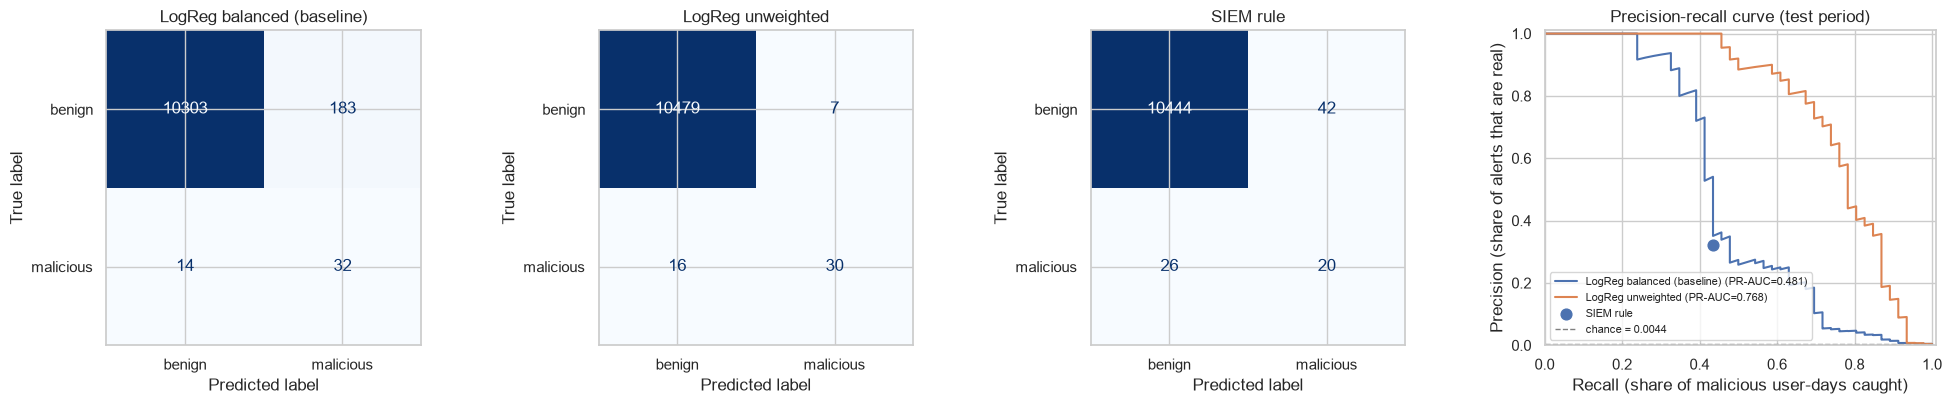

In [14]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
for a, name in zip(ax[:3], ["LogReg balanced (baseline)", "LogReg unweighted", "SIEM rule"]):
    plot_confusion(y_test, preds[name], name, ax=a)
rule_m = results["SIEM rule"]
plot_pr_curves(y_test, scores, ax=ax[3], marker_points={"SIEM rule": (rule_m["recall"], rule_m["precision"])})
plt.tight_layout(); savefig("baseline_confusion_pr"); plt.show()

Insider-level detection by the baseline (test period):


user,scenario,malicious_days_in_test,flagged_days,detected,days_to_first_flag
ASZ6559,1,10,8,True,0
EDK5757,2,23,12,True,10
ERH5833,3,3,3,True,0
JMF5791,1,10,9,True,0


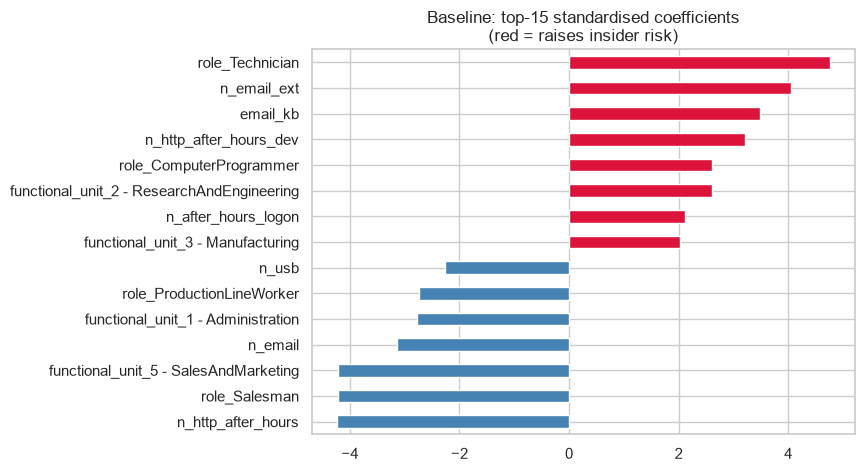

In [15]:
print("Insider-level detection by the baseline (test period):")
display(insider_level_detection(test, preds["LogReg balanced (baseline)"]).style.hide(axis="index"))

names = baseline.named_steps["prep"].get_feature_names_out()
coef = pd.Series(baseline.named_steps["clf"].coef_[0], index=[n.split("__", 1)[1] for n in names])
top = coef.reindex(coef.abs().sort_values(ascending=False).index)[:15].sort_values()
plt.figure(figsize=(7, 5)); top.plot.barh(color=np.where(top > 0, "crimson", "steelblue"))
plt.title("Baseline: top-15 standardised coefficients\n(red = raises insider risk)"); savefig("baseline_coefficients"); plt.show()

## 12. Business metric: analyst hours and cost of missed insiders

Stated assumptions (edit them in `CostAssumptions` for the customer):

* an analyst spends **20 min** triaging one alerted user-day, at a fully loaded **USD 45 / hour**;
* one missed malicious user-day costs **≈ USD 7,600**: about USD 648 k per malicious-insider incident ÷ about 85 days to
  contain (Ponemon 2022). This is a rough planning figure, not a precise loss model.

*Total cost = review cost of all alerts + cost of missed malicious user-days.* The "alert budget" column
checks the success criterion of ≤ 5 alerts per 1,000 users per day.

In [16]:
cost = CostAssumptions()
n_days, n_users = test["day"].nunique(), test["user"].nunique()
biz = pd.DataFrame({k: business_metrics(m, n_days, n_users, cost) for k, m in results.items()}).T
biz["within alert budget (≤5/1000/day)"] = biz["alerts_per_1000_users_per_day"] <= 5
display(biz.style.format({"analyst_hours": "{:.1f}", "alerts_per_day": "{:.2f}", "alerts_per_1000_users_per_day": "{:.1f}",
                          "review_cost_usd": "${:,.0f}", "missed_insider_cost_usd": "${:,.0f}", "total_cost_usd": "${:,.0f}"}))
print("Assumptions:", cost_assumptions_dict(cost))

,analyst_hours,alerts_per_day,alerts_per_1000_users_per_day,review_cost_usd,missed_insider_cost_usd,total_cost_usd,within alert budget (≤5/1000/day)
LogReg balanced (baseline),71.7,2.65,14.3,"$3,225","$106,400","$109,625",False
LogReg unweighted,12.3,0.46,2.5,$555,"$121,600","$122,155",True
SIEM rule,20.7,0.77,4.1,$930,"$197,600","$198,530",True
Always benign,0.0,0.00,0.0,$0,"$349,600","$349,600",True


Assumptions: {'analyst_minutes_per_alert': 20.0, 'analyst_cost_per_hour': 45.0, 'cost_per_missed_malicious_day': 7600.0}


In [17]:
# Save the artefacts the report and Phase 2 build on
Path("reports").mkdir(exist_ok=True)
with open("reports/phase1_metrics.json", "w") as fh:
    json.dump({"data": "synthetic CERT-r4.2 format" if USE_SYNTHETIC else "CERT r4.2",
               "cutoff": str(cutoff.date()), "split": summary.astype(str).to_dict(),
               "results": results, "business": biz.astype(object).to_dict(orient="index"),
               "cost_assumptions": cost_assumptions_dict(cost),
               "leakage_checks": checks.to_dict(orient="records")}, fh, indent=2, default=float)
res.round(4).to_csv("reports/phase1_results_table.csv")
print("Saved: data/processed/user_day_features.csv, reports/phase1_metrics.json, reports/phase1_results_table.csv, reports/figures/*.png")

Saved: data/processed/user_day_features.csv, reports/phase1_metrics.json, reports/phase1_results_table.csv, reports/figures/*.png


## 13. Phase 1 conclusions

* A **leak-free pipeline** turns five raw log types into a labelled per-user daily table; all leakage checks pass.
* The class-weighted **logistic-regression baseline** catches most malicious user-days and flags every
  test-period insider, but at threshold 0.5 its **precision is low** (too many alerts for the budget). Without
  class weights, the model is far more precise but misses a few more days. **Choosing the threshold is a
  business decision**, which Phase 2 makes explicit.
* Interesting: the *unweighted* model has the higher **PR-AUC** (it ranks better), while class weighting mostly
  shifts scores upward. With very few positives, heavy re-weighting can overfit them. Phase 2 will therefore
  compare class weights against resampling and threshold tuning, rather than assume weighting is best.
* Both ML models beat the static SIEM rule on recall and PR-AUC, so combining weak signals across log sources helps.
* Accuracy is uninformative here (an "always benign" model scores 99.6 %).

## 14. Plan and risks for Phase 2

| Phase 2 item (12 marks) | Plan |
|---|---|
| ≥ 3 models, CV tuning | **Isolation Forest** (unsupervised user-day scores), **Random Forest** and **gradient boosting** (supervised), **LOF** as a comparison; tuned with forward-chaining time-series CV on the training period only |
| Threshold for business cost | choose the threshold that minimises `total_cost_usd` under the alert budget; report the watch-list (top-k) precision |
| Explainability | **SHAP** for one false negative and one false positive, and SHAP reasons per user on the ranked watch-list |
| Robustness | **drift test** (train on early months, test on later ones) + an **evasion test** (insider spreads USB copies over normal hours) |
| Demo | Streamlit dashboard: upload logs → ranked watch-list with SHAP reasons |
| Stretch | **peer-group baselines** (each user vs their role); LSTM on daily sequences |

**Risks and mitigations**
1. *Real r4.2 size (16 GB)*: chunked http aggregation is already in place; cache the feature table to Google Drive.
2. *Very few positives (r4.2 has about 70 insiders)*: use PR-AUC and insider-level metrics, time-series CV, and class weights.
3. *Synthetic-to-real gap*: all numbers here validate the pipeline only and must be re-run on r4.2.
4. *Label granularity*: answers mark events; we label a user-day malicious if it holds ≥ 1 malicious event (documented choice).
5. *False-positive harm to staff*: alert budget, human review, and an audit of error rates per role.